# Tracing: where did the spam come from?

**COS30015 Assignment 2, Attacker or Malware Analysis, Option 1, report section 2.2.** The 60 study spam (a seeded subset of the 1,742 traced messages) are traced to the infrastructure that sent them.

## The idea in plain English

Every email carries hidden **headers** that record its journey. Each mail server that handles the message adds a `Received:` line at the top. By reading those lines, and by asking public services about the IP addresses and domain names that appear in them, we can answer questions such as: *Which country and network did this come from? Is it a hosting company? Does the sender pass the email authentication checks? Do several messages share the same infrastructure, meaning one campaign?*

A made-up `Received:` line (invented host and IP address from a range reserved for documentation) looks like this:

```
Received: from mail.example.net (mail.example.net [203.0.113.7])
        by mx.receiver.example with ESMTPS id abc123; Mon, 3 Mar 2025 10:00:00 +0000
```

It says: "the server `mx.receiver.example` received this message from `mail.example.net`, whose IP address was `203.0.113.7`, at 10:00 UTC."

## Words you will meet

| Word | Meaning |
|---|---|
| **indicator** | A fact we can look up: an IP address or a domain name. |
| **handoff IP** | The IP address that delivered the message to the receiving provider. It is written by the *receiver's own* server, so it is the most trustworthy hop. |
| **claimed origin IP** | An address from an *earlier* hop. Any earlier sender could have written a false line, so this is only a claim. |
| **SPF / DKIM / DMARC** | Three email-authentication checks. SPF: is the sending IP allowed to send for this domain? DKIM: does a digital signature match the message? DMARC: the domain owner's policy that combines the two. |
| **ASN** | Autonomous System Number: the identifier of the network (for example a hosting company) that owns an IP address. |
| **RDAP / domain age** | The public registration record of a domain. A domain registered only days before the email is a warning sign. |
| **MX record** | The DNS record that says which servers receive mail for a domain. |
| **defanging** | Writing `example[.]com` instead of `example.com` so that nobody clicks or visits it by accident. All indicators printed here are defanged. |
| **campaign** | A group of messages that share a strong indicator, so probably the same sender. |

## Stages

| Stage | Where | What |
|---|---|---|
| 2a Parse headers | `scripts/trace_parse.py` (reads raw mail, so it stays a script run with `python -I`) | `Received:` chain, handoff IP vs claimed origin IP, SPF/DKIM/DMARC, From / Return-Path / Reply-To, link domains -> `trace_headers.csv`, `trace_hops.csv` |
| 2b Enrich | section 2 below | geolocation, ASN, hosting, reputation, domain age, DNS policy for IPs and domains (indicator strings only) -> `trace_enriched.csv` |
| 2c Campaigns | section 3 below | groups emails that share a strong indicator -> `trace_campaigns.csv` |
| Results | sections 4 to 8 | the numbers and figures for section 2.2, case-study evidence, dead ends, the hand-check sheet |

**Trust tiers.** *Trusted*: the handoff hop, written by the receiving provider. *Verifiable*: what public records say about an IP or domain. *Claimed*: anything lower in the `Received:` chain, which an earlier sender could have forged.

## Safety (read this before changing anything)

* This notebook **never reads raw mail**. It reads only the CSV files written by stage 2a.
* By default it makes **no network calls**. Every lookup answer is read from `data/processed/lookup_cache.json`, and the notebook asserts that the rebuilt tables equal the saved ones.
* With `ONLINE=1` it fetches only the lookups missing from the cache, and sends **indicator strings only** (IP addresses and bare domains, never URLs). VirusTotal is read-only; urlscan.io is *search only* (nothing is submitted for scanning, so nothing visits the indicator).
* API keys come from `../.env` and are never printed.
* We never contact or scan a sender.

## 1. Setup and inputs

**What we do:** import the libraries, choose the run mode, and load the tables made by stage 2a. The `assert` lines are sanity checks: if the data is not what we expect (for example an email address leaked into a table), the notebook stops.

In [1]:
# --- Standard library ---
import csv, io, ipaddress, json, os, re, subprocess, sys, time
from collections import Counter, defaultdict
from datetime import datetime
from itertools import combinations
from pathlib import Path

# --- Third-party libraries ---
import matplotlib.pyplot as plt                                   # figures
import numpy as np                                                # arrays of numbers
import pandas as pd                                               # tables
from sklearn.feature_extraction.text import TfidfVectorizer       # text -> numbers (used to spot near-identical emails)
from sklearn.metrics.pairwise import cosine_similarity            # how similar are two texts? (0 to 1)

# --- Folders (relative to the notebooks/ folder) ---
PROC = Path("../data/processed")
RAW = Path("../data/raw")
RESULTS = Path("../results")
FIGS = Path("../figures")
SCRIPTS = Path("../scripts")

sys.path.insert(0, str(SCRIPTS))
from trace_parse import org_of      # "mail.example.co.uk" -> "example.co.uk" (shared with stage 2a)

In [2]:
# --- Run mode (set as environment variables before starting Jupyter) ---
ONLINE = os.environ.get("ONLINE", "0") == "1"          # True: fetch lookups that are missing from the cache
RUN_PARSE = os.environ.get("RUN_PARSE", "0") == "1"    # True: first rerun stage 2a (raw mail) in an isolated subprocess


def defang(indicator):
    """Make an indicator safe to print: 'example.com' -> 'example[.]com'."""
    return str(indicator).replace(".", "[.]")


if RUN_PARSE:
    # Raw mail is read only by the script, in isolated mode (-I), exactly as the project rules require.
    subprocess.run([sys.executable, "-I", "trace_parse.py", str(RAW.resolve()), str(PROC.resolve())], cwd=SCRIPTS, check=True)

In [3]:
# Load the tables written by stage 2a (one row per study email, and one row per Received hop).
emails = pd.read_csv(PROC / "emails.csv", dtype=str).fillna("")
spam = emails[emails.label == "spam"]
hdr = pd.read_csv(PROC / "trace_headers.csv", dtype=str).fillna("")     # one row per email
hops = pd.read_csv(PROC / "trace_hops.csv", dtype=str).fillna("")       # one row per Received hop

# Sanity checks: 60 emails, the same 60 everywhere, and no email address in any trace table.
assert len(spam) == len(hdr) == 60 and set(hdr.id) == set(spam.id)
assert not any("@" in str(value) for table in (hdr, hops) for value in table.to_numpy().ravel()), "an address leaked into the trace tables"

mode = "ONLINE (fetch missing lookups)" if ONLINE else "offline (cache only)"
print(f"{len(hdr)} study spam; {len(hops)} Received hops; hop roles {hops.role.value_counts().to_dict()}; mode: {mode}")
hdr.groupby("corpus").size().rename("emails").to_frame()

60 study spam; 185 Received hops; hop roles {'claimed': 65, 'handoff': 60, 'internal': 60}; mode: offline (cache only)


,emails
corpus,
guenter-2026-10,15
nazario-2024,10
nazario-2025,20
phishing-pot,15


## 2. Stage 2b: enrichment (indicator strings only)

**What we do:** for each IP address and domain, ask public services what they know about it, and keep the answers in a local file (`lookup_cache.json`) so the notebook never needs the internet again. Only real answers (including "not found") are cached, never temporary errors.

| Indicator | Services |
|---|---|
| IP address | ip-api (country, ASN, ISP, hosting and proxy flags, reverse DNS), AbuseIPDB (abuse score, reports), VirusTotal (engine verdicts), urlscan.io search (how many public scans exist) |
| Domain | RDAP (registration date, registrar), DNS (MX, SPF, DMARC policy), VirusTotal, urlscan.io search |

**The pivot link host.** Each email's main link domain (chosen in stage 2a) is looked up *unless* it belongs to an abused legitimate service (file-sharing, newsletter or storage platforms): the age and reputation of such a service says nothing about the sender.

**Domain age** = time between registration and receipt. A negative age means the domain lapsed and was re-registered after the email, so it is left blank.

### The cache

`Cache.get()` is the one door every lookup goes through:

1. If the answer is already saved, return it.
2. If we are offline, note it as "missing" and return nothing.
3. If online, wait long enough to respect the service's rate limit, ask, save the answer and return it.

In [4]:
# Pauses (in seconds) between calls, to stay inside each free service's rate limit.
VT_GAP_S, IPAPI_GAP_S, RDAP_GAP_S, TIMEOUT = 15.5, 1.5, 1.0, 20


class Cache:
    """A saved dictionary of 'service:indicator' -> answer.
    Offline mode only reads it; online mode fetches what is missing and saves after every answer."""

    def __init__(self, path):
        self.path = path
        self.data = json.loads(path.read_text(encoding="utf-8")) if path.exists() else {}
        self.last_call = {}     # service -> time of its last call (for rate limiting)
        self.missing = []       # lookups we wanted but could not do

    def get(self, service, indicator, gap, fetch):
        key = f"{service}:{indicator}"
        if key in self.data:                      # 1. already saved
            return self.data[key]
        if not ONLINE:                            # 2. offline: remember that it is missing
            self.missing.append(key)
            return {}
        # 3. online: respect the rate limit, then ask the service
        wait = gap - (time.time() - self.last_call.get(service, 0))
        if wait > 0:
            time.sleep(wait)
        self.last_call[service] = time.time()
        try:
            result = fetch(indicator)
        except Exception as error:      # print the error TYPE only: a message could echo a URL that contains a key
            print(f"  {service}: {type(error).__name__} (not cached, retry next run)")
            return {"error": type(error).__name__}
        if result.get("retry"):
            print(f"  {service}: HTTP {result['retry']} (not cached, retry next run)")
            return {"error": result["retry"]}
        self.data[key] = result
        self.path.write_text(json.dumps(self.data, indent=0), encoding="utf-8")
        return result

### One small function per service

Each function below asks one service about one indicator and keeps only the fields we use. They run **only in online mode**; offline, the answers come from the cache.

In [5]:
def http_json(url, headers=None):
    """GET a URL and return its JSON. A 404 means 'not found'; any other failure is reported as {'retry': status}."""
    import requests
    response = requests.get(url, headers=headers, timeout=TIMEOUT)
    if response.status_code == 404:
        return {"not_found": True}
    return {"retry": response.status_code} if response.status_code != 200 else response.json()


def ipapi(ip):
    """ip-api: country, network owner, ASN, reverse DNS, hosting / proxy flags."""
    answer = http_json(f"http://ip-api.com/json/{ip}?fields=status,country,countryCode,isp,org,as,asname,reverse,proxy,hosting,mobile")
    if answer.get("retry") or answer.get("not_found"):
        return answer
    return {field: answer.get(field) for field in ("country", "countryCode", "isp", "org", "as", "asname", "reverse", "proxy", "hosting", "mobile")}


def abuseipdb(key):
    """AbuseIPDB: how often has this IP been reported for abuse? (returns a fetch function that holds the API key)"""
    def fetch(ip):
        answer = http_json(f"https://api.abuseipdb.com/api/v2/check?ipAddress={ip}&maxAgeInDays=90", {"Key": key, "Accept": "application/json"})
        answer = answer.get("data", answer)
        if answer.get("retry") or answer.get("not_found"):
            return answer
        return {field: answer.get(field) for field in ("abuseConfidenceScore", "totalReports", "usageType", "isTor", "domain")}
    return fetch


def virustotal(key, kind):
    """VirusTotal (read-only): how many security engines flag this IP or domain? kind = 'ip_addresses' or 'domains'."""
    def fetch(indicator):
        answer = http_json(f"https://www.virustotal.com/api/v3/{kind}/{indicator}", {"x-apikey": key})
        if answer.get("retry") or answer.get("not_found"):
            return answer
        attributes = answer["data"]["attributes"]
        stats = attributes.get("last_analysis_stats", {})
        return {"malicious": stats.get("malicious", 0), "suspicious": stats.get("suspicious", 0), "harmless": stats.get("harmless", 0),
                "as_owner": attributes.get("as_owner"), "registrar": attributes.get("registrar"), "created": attributes.get("creation_date"),
                "categories": sorted(set((attributes.get("categories") or {}).values()))[:4]}
    return fetch


def urlscan(key):
    """urlscan.io SEARCH of scans other people already ran. Nothing is submitted, so urlscan never visits the indicator."""
    def fetch(indicator):
        import requests
        try:
            ipaddress.ip_address(indicator)
            query = f'ip:"{indicator}"'          # it is an IP address
        except ValueError:
            query = f"domain:{indicator}"        # otherwise it is a domain
        response = requests.get("https://urlscan.io/api/v1/search/", params={"q": query, "size": 1}, headers={"API-Key": key}, timeout=TIMEOUT)
        if response.status_code != 200:
            return {"retry": response.status_code}
        answer = response.json()
        return {"total": answer.get("total", 0), "last_scan": (answer.get("results") or [{}])[0].get("task", {}).get("time")}
    return fetch


def rdap(domain):
    """RDAP: the public registration record of a domain (registration date and registrar)."""
    answer = http_json(f"https://rdap.org/domain/{domain}")
    if answer.get("retry") or answer.get("not_found"):
        return answer
    events = {event.get("eventAction"): event.get("eventDate") for event in answer.get("events", [])}
    registrar = next((item[3] for entity in answer.get("entities", []) if "registrar" in entity.get("roles", [])
                      for item in [x for x in entity.get("vcardArray", [None, []])[1] if x[0] == "fn"]), "")
    return {"registered": events.get("registration"), "registrar": registrar}


def dns_info(domain):
    """DNS: does the domain receive mail (MX), and what are its SPF and DMARC policies?"""
    import dns.resolver

    def txt_records(name):
        try:
            return [b"".join(record.strings).decode("utf-8", "replace") for record in dns.resolver.resolve(name, "TXT", lifetime=5)]
        except Exception:
            return []

    try:
        mx_count = len(dns.resolver.resolve(domain, "MX", lifetime=5))
    except Exception:
        mx_count = 0
    spf = next((t for t in txt_records(domain) if t.lower().startswith("v=spf1")), "")
    dmarc = next((t for t in txt_records(f"_dmarc.{domain}") if t.lower().startswith("v=dmarc1")), "")
    return {"mx": mx_count, "spf": (spf.split()[-1] if spf else ""), "dmarc_policy": (re.search(r"\bp=(\w+)", dmarc) or [None, ""])[1]}

### Collect the indicators and run the lookups

First we list every indicator that appears in the 60 emails (IP addresses, sender domains, link hosts), then we look each one up through the cache.

In [6]:
study_rows = hdr.to_dict("records")       # one dictionary per email

# When did the recipient side receive each message? (hop 0). Used later to work out how old a domain was at that moment.
first_hop_time = {}
for hop in hops.to_dict("records"):
    first_hop_time.setdefault(hop["id"], hop["time_utc"])

# The indicators to look up.
ips = sorted({row[col] for row in study_rows for col in ("handoff_ip", "claimed_origin_ip") if row[col]})
sender_domains = sorted({row[col] for row in study_rows for col in ("from_domain", "return_path_domain", "reply_to_domain") if row[col]})
link_service = {row["id"]: row["pivot_service"] for row in study_rows}        # which abused service hosts the link, if any
pivot_host = {row["id"]: row["pivot_link_host"] for row in study_rows}        # the main link host of each email
own_link_host = {row["id"]: row["pivot_link_host"] for row in study_rows if row["pivot_link_host"] and not row["pivot_service"]}
registrable_domains = sorted({org_of(x) for x in sender_domains + list(own_link_host.values()) if org_of(x)})
hosts_to_scan = sorted(set(own_link_host.values()) | set(sender_domains))      # what we ask urlscan.io about

print(f"indicators: {len(ips)} IPs, {len(sender_domains)} sender domains, {len(registrable_domains)} registrable domains (sender + top link host)")

indicators: 92 IPs, 78 sender domains, 100 registrable domains (sender + top link host)


In [7]:
cache = Cache(PROC / "lookup_cache.json")

# API keys are read only in online mode, from the git-ignored .env file, and are never printed.
env = {}
if ONLINE:
    lines = Path("../.env").read_text().splitlines()
    env = dict(line.strip().split("=", 1) for line in lines if "=" in line and not line.startswith("#"))
    print("online: fetching what is missing (VirusTotal is slow, 4 per minute)")

# Ask every service about every indicator it understands. Offline, each call just reads the cache.
for ip in ips:
    cache.get("ipapi", ip, IPAPI_GAP_S, ipapi)
for domain in registrable_domains:
    cache.get("rdap", domain, RDAP_GAP_S, rdap)
for domain in sender_domains:
    cache.get("dns", domain, 0, dns_info)
for ip in ips:
    cache.get("abuseipdb", ip, 0.3, abuseipdb(env.get("ABUSEIPDB_KEY")))
for indicator in ips + hosts_to_scan:
    cache.get("urlscan", indicator, 0.6, urlscan(env.get("URLSCAN_KEY")))
for ip in ips:
    cache.get("vt_ip", ip, VT_GAP_S, virustotal(env.get("VT_KEY"), "ip_addresses"))
for domain in registrable_domains:
    cache.get("vt_dom", domain, VT_GAP_S, virustotal(env.get("VT_KEY"), "domains"))

print(f"cached answers: {len(cache.data)}; lookups missing from the cache: {len(cache.missing)}")
print("missing by service (never cached: the service returned no usable answer, e.g. VirusTotal HTTP 400):",
      dict(Counter(key.split(":")[0] for key in cache.missing)))
print("these stay empty in the tables, exactly as in the original run; ONLINE=1 would retry them")

cached answers: 781; lookups missing from the cache: 3
missing by service (never cached: the service returned no usable answer, e.g. VirusTotal HTTP 400): {'vt_dom': 3}
these stay empty in the tables, exactly as in the original run; ONLINE=1 would retry them


### Build the enrichment table

One row per email, combining the header facts with everything the lookups said. The result must equal the saved `trace_enriched.csv`.

In [8]:
def cached_answer(service_name, indicator):
    """The saved answer for one indicator, or an empty dictionary if there is none."""
    return cache.data.get(f"{service_name}:{indicator}", {}) if indicator else {}


def age_days(registered, received):
    """Days between a domain's registration and the moment the email arrived ('' if unknown or negative)."""
    try:
        days = (datetime.fromisoformat(received) - datetime.fromisoformat(registered.replace("Z", "+00:00"))).days
    except (TypeError, ValueError, AttributeError):
        return ""
    return days if days >= 0 else ""     # negative: lapsed and re-registered after the email; RDAP shows only the current registration


enriched_rows = []
for msg in study_rows:
    row = dict(id=msg["id"], corpus=msg["corpus"])

    # (a) facts about the two IP addresses: the trusted handoff and the claimed origin
    for prefix, ip in (("handoff", msg["handoff_ip"]), ("claimed", msg["claimed_origin_ip"])):
        geo, abuse, virustotal_ip = cached_answer("ipapi", ip), cached_answer("abuseipdb", ip), cached_answer("vt_ip", ip)
        row.update({f"{prefix}_ip": ip,
                    f"{prefix}_country": geo.get("countryCode"),
                    f"{prefix}_asn": geo.get("as"),
                    f"{prefix}_org": geo.get("org") or geo.get("isp"),
                    f"{prefix}_hosting": geo.get("hosting"),
                    f"{prefix}_proxy": geo.get("proxy"),
                    f"{prefix}_rdns": geo.get("reverse"),
                    f"{prefix}_abuse_score": abuse.get("abuseConfidenceScore"),
                    f"{prefix}_abuse_reports": abuse.get("totalReports"),
                    f"{prefix}_vt_malicious": virustotal_ip.get("malicious"),
                    f"{prefix}_urlscan_scans": cached_answer("urlscan", ip).get("total")})

    # (b) facts about the two domains: the From domain and the main link domain
    row["link_service"] = link_service[msg["id"]]
    for prefix, domain in (("from", msg["from_domain"]), ("link", pivot_host[msg["id"]])):
        is_abused_service = (prefix == "link" and link_service[msg["id"]] != "")    # a legitimate service says nothing about the sender
        registrable = "" if is_abused_service else org_of(domain)
        scan_key = "" if is_abused_service else domain
        registration, virustotal_domain, dns_answer = cached_answer("rdap", registrable), cached_answer("vt_dom", registrable), cached_answer("dns", domain)
        row.update({f"{prefix}_domain": domain,
                    f"{prefix}_registrar": registration.get("registrar") or virustotal_domain.get("registrar"),
                    f"{prefix}_age_days_at_receipt": age_days(registration.get("registered"), first_hop_time.get(msg["id"], "")),
                    f"{prefix}_vt_malicious": virustotal_domain.get("malicious"),
                    f"{prefix}_urlscan_scans": cached_answer("urlscan", scan_key).get("total"),
                    f"{prefix}_urlscan_last": cached_answer("urlscan", scan_key).get("last_scan")})
        if prefix == "from":
            row.update(from_has_mx=dns_answer.get("mx"), from_spf_all=dns_answer.get("spf"), from_dmarc_policy=dns_answer.get("dmarc_policy"))
    enriched_rows.append(row)

In [9]:
# Write the rows to an in-memory CSV and read them back, so that every value becomes text exactly as it is in the saved file.
buffer = io.StringIO()
writer = csv.DictWriter(buffer, fieldnames=list(enriched_rows[0]))
writer.writeheader()
writer.writerows(enriched_rows)
enriched = pd.read_csv(io.StringIO(buffer.getvalue()), dtype=str).fillna("")
assert len(enriched) == 60 and not enriched.apply(lambda col: col.str.contains("@")).any().any()    # still no email addresses

# Safety net (offline): the rebuilt table must equal the saved one. Online: the saved file is refreshed.
saved_enriched = pd.read_csv(PROC / "trace_enriched.csv", dtype=str).fillna("")
if not ONLINE:
    pd.testing.assert_frame_equal(enriched, saved_enriched)
    print("enrichment rebuilt from the cache equals data/processed/trace_enriched.csv")
else:
    (PROC / "trace_enriched.csv").write_text(buffer.getvalue(), encoding="utf-8", newline="")
    print("trace_enriched.csv rewritten from the updated cache")

# The first five rows, with the indicators defanged.
enriched[["id", "corpus", "handoff_country", "handoff_asn", "handoff_hosting", "from_domain", "link_domain"]].head(5).assign(
    handoff_asn=lambda table: table.handoff_asn.map(defang),
    from_domain=lambda table: table.from_domain.map(defang),
    link_domain=lambda table: table.link_domain.map(defang))

enrichment rebuilt from the cache equals data/processed/trace_enriched.csv


,id,corpus,handoff_country,handoff_asn,handoff_hosting,from_domain,link_domain
0,s001,nazario-2025,US,"AS19871 Network Solutions, LLC",True,doraldentalstudio[.]com,mail[.]dhcngroup[.]com
1,s002,nazario-2025,US,AS399646 Snaju Development,True,whoochieenterprise[.]eu,www[.]careerboostconsulting[.]com
2,s003,nazario-2025,US,"AS55293 A2 Hosting, Inc[.]",True,uac[.]co[.]nz,
3,s004,nazario-2025,US,AS36352 HostPapa,True,al-beker[.]com,prickle-economic-origami[.]glitch[.]me
4,s005,nazario-2025,PL,AS34360 Cyber_Folks S[.]A[.],True,digimer[.]pl,sertec-py[.]com


## 3. Stage 2c: campaigns

**What we do:** find groups of emails that were probably sent by the same operation.

**The rule.** Two emails are linked only by a **strong** shared indicator:

* the same own-domain link host, the same From domain, or the same Reply-To domain,
* the same handoff IP or the same claimed-origin IP, or
* near-identical text (TF-IDF cosine similarity of at least 0.80).

Big shared providers (Google, Microsoft, mail relays) never link two emails: two messages both sent through Gmail says nothing about who sent them. ASN, registrar and hosting flag are only supporting evidence and never merge anything.

**Grouping.** If A is linked to B and B to C, then A, B and C are one campaign (a *connected group*). An email with no link is a *singleton*. The small `find_group_leader` function below is a standard "union-find" trick for building such groups.

In [10]:
TEXT_SIM = 0.80     # texts at least this similar count as near-identical
SHARED_PROVIDERS = {"google.com", "outlook.com", "gmail.com", "yahoo.com", "hotmail.com", "microsoft.com", "secureserver.net"}

clean = pd.read_csv(PROC / "clean.csv", dtype=str).fillna("")
campaign_input = (enriched
                  .merge(hdr[["id", "reply_to_domain", "pivot_link_host", "pivot_service", "year"]], on="id")
                  .merge(clean[["id", "text"]], on="id"))
assert len(campaign_input) == 60
ids = campaign_input["id"].tolist()

# Step 1: for every strong indicator, collect the ids of the emails that share it.
shared_by = defaultdict(set)            # (kind of indicator, value) -> set of email ids
for msg in campaign_input.itertuples():
    own_pivot = msg.pivot_link_host if not msg.pivot_service else ""
    indicators = (("link host", org_of(own_pivot)),
                  ("sender domain", org_of(msg.from_domain)),
                  ("reply-to domain", org_of(msg.reply_to_domain)),
                  ("handoff IP", msg.handoff_ip),
                  ("claimed IP", msg.claimed_ip))
    for kind, value in indicators:
        if value and value not in SHARED_PROVIDERS:
            shared_by[(kind, value)].add(msg.id)

# Step 2: near-identical text. Compare every pair of emails (1,770 pairs for 60 emails).
text_similarity = cosine_similarity(TfidfVectorizer(sublinear_tf=True, min_df=1).fit_transform(campaign_input.text))
for i, j in combinations(range(len(ids)), 2):
    if text_similarity[i, j] >= TEXT_SIM:
        shared_by[("near-identical text", f"{ids[i]}~{ids[j]}")] |= {ids[i], ids[j]}

In [11]:
# Step 3: merge linked emails into groups. Every email starts as its own group leader; linking two emails
# makes one group's leader point at the other's.
leader = {msg_id: msg_id for msg_id in ids}


def find_group_leader(msg_id):
    """Follow the 'leader' pointers until we reach the email that leads the group."""
    while leader[msg_id] != msg_id:
        leader[msg_id] = leader[leader[msg_id]]      # shortcut, so later look-ups are fast
        msg_id = leader[msg_id]
    return msg_id


for linked_ids in shared_by.values():
    linked_ids = sorted(linked_ids)
    for other in linked_ids[1:]:
        leader[find_group_leader(other)] = find_group_leader(linked_ids[0])

groups = defaultdict(list)
for msg_id in ids:
    groups[find_group_leader(msg_id)].append(msg_id)

# Keep real campaigns (2+ emails), biggest first, and number them C01, C02, ...
campaign_groups = sorted((sorted(group) for group in groups.values() if len(group) > 1), key=lambda g: (-len(g), g[0]))
campaign_name = {msg_id: f"C{number:02d}" for number, group in enumerate(campaign_groups, 1) for msg_id in group}

# For each email, which indicators link it to others (defanged)? Used as evidence in the report.
link_evidence = defaultdict(list)
for (kind, value), linked_ids in shared_by.items():
    if len(linked_ids) > 1:
        for msg_id in linked_ids:
            link_evidence[msg_id].append(f"{kind}={defang(value)}")

campaigns = pd.DataFrame({"id": campaign_input.id,
                          "campaign": campaign_input.id.map(campaign_name).fillna(""),
                          "links": campaign_input.id.map(lambda msg_id: " | ".join(sorted(set(link_evidence[msg_id]))))})

# Safety net: must equal the saved table.
pd.testing.assert_frame_equal(campaigns, pd.read_csv(PROC / "trace_campaigns.csv", dtype=str).fillna(""))
covered = sum(len(group) for group in campaign_groups)
print(f"{len(campaign_groups)} campaigns covering {covered} of 60 emails; {60 - covered} singletons (equals data/processed/trace_campaigns.csv)")

6 campaigns covering 16 of 60 emails; 44 singletons (equals data/processed/trace_campaigns.csv)


In [12]:
# One summary row per campaign.
by_id = campaign_input.set_index("id")
campaign_summary = []
for number, group in enumerate(campaign_groups, 1):
    members = by_id.loc[group]
    campaign_summary.append(dict(
        campaign=f"C{number:02d}",
        emails=len(group),
        ids=",".join(group),
        corpora=dict(members.corpus.value_counts()),
        linked_by=", ".join(sorted({link.split("=")[0] for msg_id in group for link in link_evidence[msg_id]})),
        top_handoff_asn=defang(members.handoff_asn.value_counts().index[0]) if members.handoff_asn.str.len().any() else "",
        years=sorted(set(members.year))))
pd.DataFrame(campaign_summary)

,campaign,emails,ids,corpora,linked_by,top_handoff_asn,years
0,C01,4,"s046,s047,s056,s060",{'phishing-pot': 4},"claimed IP, handoff IP, link host, reply-to do...",AS8075 Microsoft Corporation,[2026]
1,C02,3,"s033,s037,s041",{'guenter-2026-10': 3},link host,AS396982 Google LLC,[2026]
2,C03,3,"s053,s054,s055",{'phishing-pot': 3},link host,AS16276 OVH SAS,[2026]
3,C04,2,"s001,s030","{'nazario-2025': 1, 'nazario-2024': 1}",claimed IP,"AS19871 Network Solutions, LLC",[2024]
4,C05,2,"s024,s025",{'nazario-2024': 2},near-identical text,AS15169 Google LLC,[2024]
5,C06,2,"s048,s049",{'phishing-pot': 2},link host,AS16276 OVH SAS,[2026]


## 4. Results for section 2.2: where the spam came from

**What we do:** count things. Every number below is computed here from the tables above (60 study spam); counts are of emails unless noted. The printed lines are the figures quoted in the report.

In [13]:
# Join the enrichment table with the header flags (SPF/DKIM/DMARC, mismatches, ...).
study = enriched.merge(hdr[["id", "spf", "dkim", "dmarc", "from_ne_return_path", "from_ne_reply_to",
                            "pivot_link_host", "pivot_service", "timestamps_backwards", "same_as_handoff"]], on="id")


def to_number(column):
    """Text column -> numbers (anything that is not a number becomes NaN)."""
    return pd.to_numeric(column, errors="coerce")


def is_true(column):
    """Text column -> True where the text says true / 1 / yes."""
    return column.astype(str).str.lower().isin(["true", "1", "yes"])


print("handoff IP country:", study.handoff_country.value_counts().head(6).to_dict())
print("claimed origin IP country:", study.claimed_country.value_counts().head(6).to_dict())
print(f"handoff IP on a hosting / cloud network: {int(is_true(study.handoff_hosting).sum())} of 60")
print(f"AbuseIPDB score >= 25 (handoff IP): {int((to_number(study.handoff_abuse_score) >= 25).sum())}")
print(f"VirusTotal flags (>= 1 engine): link host {int((to_number(study.link_vt_malicious) > 0).sum())}, "
      f"From domain {int((to_number(study.from_vt_malicious) > 0).sum())}, handoff IP {int((to_number(study.handoff_vt_malicious) > 0).sum())}")

print("\nauthentication (SPF / DKIM / DMARC):")
for check in ("spf", "dkim", "dmarc"):
    print(f"   {check.upper():5}", study[check].replace("", "none").value_counts().to_dict())
print(f"\nFrom differs from Return-Path: {int(is_true(study.from_ne_return_path).sum())}; "
      f"From differs from Reply-To: {int(is_true(study.from_ne_reply_to).sum())}")

handoff IP country: {'US': 30, 'FR': 5, 'IN': 3, 'AU': 3, 'NL': 3, 'CA': 3}
claimed origin IP country: {'US': 23, 'NL': 5, 'CA': 5, 'FR': 4, 'RO': 3, 'GB': 3}
handoff IP on a hosting / cloud network: 50 of 60
AbuseIPDB score >= 25 (handoff IP): 3
VirusTotal flags (>= 1 engine): link host 12, From domain 8, handoff IP 9

authentication (SPF / DKIM / DMARC):
   SPF   {'pass': 30, 'none': 22, 'softfail': 6, 'fail': 1, 'temperror': 1}
   DKIM  {'pass': 30, 'none': 29, 'fail': 1}
   DMARC {'none': 35, 'pass': 22, 'temperror': 2, 'permerror': 1}

From differs from Return-Path: 10; From differs from Reply-To: 12


In [14]:
# The link in each email points either to the spammer's own domain, or to an abused legitimate service, or nowhere usable.
own_domain = study[(study.pivot_link_host != "") & (study.pivot_service == "")]
print(f"link pivot: own domain {len(own_domain)}, abused legitimate service {int((study.pivot_service != '').sum())}, "
      f"no usable link {int((study.pivot_link_host == '').sum())}")

domain_age = to_number(own_domain.link_age_days_at_receipt)
print(f"own-domain link hosts with a known age: {int(domain_age.notna().sum())}; median {domain_age.median() / 30.44:.0f} months; "
      f"under 90 days: {int((domain_age < 90).sum())}")

scans = to_number(own_domain.link_urlscan_scans)
print(f"own-domain link hosts flagged by VirusTotal: {int((to_number(own_domain.link_vt_malicious) > 0).sum())}; "
      f"with public urlscan scans: {int((scans > 0).sum())} of {len(own_domain)} (median {scans[scans > 0].median():.0f} scans)")

# The same checks split by source corpus.
study.groupby("corpus").agg(
    emails=("id", "size"),
    spf_pass=("spf", lambda s: int((s == "pass").sum())),
    dkim_pass=("dkim", lambda s: int((s == "pass").sum())),
    dmarc_pass=("dmarc", lambda s: int((s == "pass").sum())),
    hosting=("handoff_hosting", lambda s: int(is_true(s).sum())))

link pivot: own domain 40, abused legitimate service 14, no usable link 6
own-domain link hosts with a known age: 34; median 22 months; under 90 days: 9
own-domain link hosts flagged by VirusTotal: 12; with public urlscan scans: 29 of 40 (median 16 scans)


,emails,spf_pass,dkim_pass,dmarc_pass,hosting
corpus,,,,,
guenter-2026-10,15,0,0,0,12
nazario-2024,10,6,9,5,7
nazario-2025,20,16,16,12,18
phishing-pot,15,8,5,5,13


In [15]:
# The networks that delivered the most spam (the trusted handoff hop). A network name identifies a company, not a person.
networks = (study.assign(network=study.handoff_org.where(study.handoff_org != "", "unknown"))
            .groupby("network")
            .agg(emails=("id", "size"), country=("handoff_country", lambda s: s.mode().iat[0]))
            .sort_values("emails", ascending=False))
networks.head(10)

,emails,country
network,,
Google LLC,4,US
HostPapa,4,US
Microsoft Azure Cloud (eastus2),4,US
Google Cloud (us-east1),3,US
RackNerd LLC,3,US
Google Cloud (us-central1),2,US
Rezallah Madonna,2,FR
Contabo GmbH,1,FR
"1GSERVERS, LLC",1,US


## 5. Dead ends and what the evidence cannot show

**What we do:** count the situations that stop a trace from going further. Tracing never ends at a person: it ends at a server, a provider or a forged line. These counts belong in the attribution-limits paragraph of the report.

In [16]:
claimed_hops = hops[hops.role == "claimed"]


def is_private_or_loopback(ip):
    """True for addresses such as 10.x.x.x or 127.0.0.1, which cannot be a real public sender."""
    if not ip:
        return False
    address = ipaddress.ip_address(ip)
    return address.is_private or address.is_loopback


# Per email: does any claimed hop have a private or loopback address?
has_private_hop = claimed_hops.from_ip.map(is_private_or_loopback).groupby(claimed_hops.id).any()

dead_ends = {
    "no authentication header at all (SPF, DKIM and DMARC all empty)": int(((hdr.spf == "") & (hdr.dkim == "") & (hdr.dmarc == "")).sum()),
    "claimed hop is a private or loopback address (forged or internal)": int(has_private_hop.sum()),
    "timestamps go backwards in the chain": int(is_true(hdr.timestamps_backwards).sum()),
    "claimed origin IP equals the handoff IP (no earlier hop visible)": int(is_true(hdr.same_as_handoff).sum()),
    "link hides behind an abused legitimate service": int((hdr.pivot_service != "").sum()),
    "no usable link host": int((hdr.pivot_link_host == "").sum()),
    "handoff IP is a large shared provider (Google, Microsoft, Amazon...)": int(enriched.handoff_org.str.contains("Google|Microsoft|Amazon|Azure", case=False).sum()),
}
pd.Series(dead_ends, name="emails (of 60)").to_frame()

,emails (of 60)
"no authentication header at all (SPF, DKIM and DMARC all empty)",13
claimed hop is a private or loopback address (forged or internal),9
timestamps go backwards in the chain,0
claimed origin IP equals the handoff IP (no earlier hop visible),26
link hides behind an abused legitimate service,14
no usable link host,6
"handoff IP is a large shared provider (Google, Microsoft, Amazon...)",23


## 6. Figure: country of the sending IP and authentication results

Left: the country of the trusted handoff IP (blue) against the country of the claimed origin IP (orange, forgeable). Right: how many emails passed, failed or had no result for each authentication check.

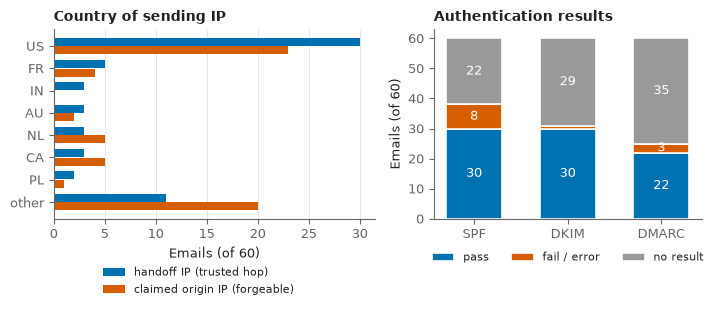

In [17]:
INK, MUTED, GRID = "#222222", "#666666", "#DDDDDD"
BLUE, VERMILION, GREY = "#0072B2", "#D55E00", "#999999"
plt.rcParams.update({"font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False})

fig, (ax_country, ax_auth) = plt.subplots(1, 2, figsize=(7.4, 3.3), gridspec_kw={"width_ratios": [1.2, 1]})

# --- Left: the 7 most common handoff countries plus "other" ---
handoff_counts = enriched.handoff_country.value_counts()
claimed_counts = enriched.claimed_country.value_counts()
top_countries = list(handoff_counts.head(7).index)
labels = top_countries + ["other"]
handoff_values = [int(handoff_counts.get(c, 0)) for c in top_countries] + [int(handoff_counts[~handoff_counts.index.isin(top_countries)].sum())]
claimed_values = [int(claimed_counts.get(c, 0)) for c in top_countries] + [int(claimed_counts[~claimed_counts.index.isin(top_countries)].sum())]
y_positions = np.arange(len(labels))[::-1]
ax_country.barh(y_positions + 0.19, handoff_values, height=0.36, color=BLUE, label="handoff IP (trusted hop)")
ax_country.barh(y_positions - 0.19, claimed_values, height=0.36, color=VERMILION, label="claimed origin IP (forgeable)")
ax_country.set_yticks(y_positions, labels)
ax_country.set_xlabel("Emails (of 60)")
ax_country.grid(axis="x", color=GRID, lw=0.5)
ax_country.set_axisbelow(True)
ax_country.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.45, -0.2))
ax_country.set_title("Country of sending IP", loc="left", fontweight="bold", fontsize=10)

# --- Right: stacked bars of pass / fail-or-error / no result for SPF, DKIM, DMARC ---
auth_counts = []      # (name, pass, fail or error, no result)
for check in ("spf", "dkim", "dmarc"):
    result = hdr[check].replace("", "none")
    auth_counts.append((check.upper(), int((result == "pass").sum()), int((~result.isin(["pass", "none"])).sum()), int((result == "none").sum())))
x_positions = np.arange(len(auth_counts))
for name, colour, column in (("pass", BLUE, 1), ("fail / error", VERMILION, 2), ("no result", GREY, 3)):
    bottoms = np.array([sum(row[1:column]) for row in auth_counts])      # stack on top of the earlier segments
    values = np.array([row[column] for row in auth_counts])
    ax_auth.bar(x_positions, values, bottom=bottoms, color=colour, width=0.6, edgecolor="white", linewidth=1.2, label=name)
    for x, (bottom, value) in enumerate(zip(bottoms, values)):
        if value >= 3:      # only label segments big enough to hold the number
            ax_auth.text(x, bottom + value / 2, str(value), ha="center", va="center", color="white", fontsize=9)
ax_auth.set_xticks(x_positions, [row[0] for row in auth_counts])
ax_auth.set_ylabel("Emails (of 60)")
ax_auth.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
ax_auth.set_title("Authentication results", loc="left", fontweight="bold", fontsize=10)

fig.tight_layout()
fig.savefig(FIGS / "char_origin_auth.png", dpi=200)
plt.show()

## 7. Case-study evidence (defanged)

**What we do:** print an *evidence card* for each candidate case study: the `Received:` hops (oldest claim first) and the key enrichment and authentication facts. IP addresses and hostnames are defanged and no email address appears. These cards are the raw material for the write-up; the interpretation goes in the report.

In [18]:
# Which emails to show, and why they are interesting.
CASES = {
    "C01: one Azure IP, shared link and Reply-To, abused newsletter service": [i for group in campaign_groups if "s046" in group for i in group][:4] or ["s046"],
    "C04: two compromised US hosts relaying via one Romanian IP": ["s001", "s030"],
    "Gmail relay abuse": ["s025"],
    "Honeypot message with forged hops and a Gmail Reply-To": ["s035"],
    "Full Received-chain walkthrough": ["s050"],
}
study_by_id = study.set_index("id")
headers_by_id = hdr.set_index("id")
campaign_by_id = campaigns.set_index("id")
HOP_ORDER = {"claimed": 0, "handoff": 1, "internal": 2}      # print the oldest claims first, the trusted handoff after


def print_evidence_card(msg_id):
    facts, header = study_by_id.loc[msg_id], headers_by_id.loc[msg_id]
    print(f"\n  {msg_id} ({facts.corpus}, {header.year}); campaign {campaign_by_id.loc[msg_id, 'campaign'] or 'none'}")
    print(f"    handoff IP {defang(facts.handoff_ip)} in {facts.handoff_country}, {defang(facts.handoff_asn)} {facts.handoff_org}; "
          f"hosting {facts.handoff_hosting}; AbuseIPDB {facts.handoff_abuse_score}; VirusTotal {facts.handoff_vt_malicious}")
    print(f"    claimed IP {defang(facts.claimed_ip)} in {facts.claimed_country}, {defang(facts.claimed_asn)} {facts.claimed_org}")
    print(f"    From domain {defang(facts.from_domain)} (age {facts.from_age_days_at_receipt} d, VT {facts.from_vt_malicious}); "
          f"Reply-To domain {defang(header.reply_to_domain)}; From!=Return-Path {header.from_ne_return_path}; From!=Reply-To {header.from_ne_reply_to}")
    print(f"    link {defang(facts.link_domain)} (service: {facts.link_service or 'own domain'}; age {facts.link_age_days_at_receipt} d; VT {facts.link_vt_malicious}); "
          f"SPF {header.spf or 'none'}, DKIM {header.dkim or 'none'}, DMARC {header.dmarc or 'none'}")
    message_hops = (hops[hops.id == msg_id]
                    .assign(order=lambda t: t.role.map(HOP_ORDER), hop=lambda t: t.hop.astype(int))
                    .sort_values(["order", "hop"], ascending=[True, False]))
    printable = message_hops[["role", "from_host", "from_ip", "by_host", "time_utc"]].assign(
        from_host=lambda t: t.from_host.map(defang), from_ip=lambda t: t.from_ip.map(defang), by_host=lambda t: t.by_host.map(defang))
    print(printable.to_string(index=False))

In [19]:
for title, case_ids in CASES.items():
    print("=" * 100)
    print(title)
    for msg_id in case_ids:
        print_evidence_card(msg_id)

C01: one Azure IP, shared link and Reply-To, abused newsletter service

  s046 (phishing-pot, 2026); campaign C01
    handoff IP 20[.]114[.]192[.]242 in US, AS8075 Microsoft Corporation Microsoft Azure Cloud (eastus2); hosting True; AbuseIPDB 10; VirusTotal 0
    claimed IP 20[.]114[.]192[.]242 in US, AS8075 Microsoft Corporation Microsoft Azure Cloud (eastus2)
    From domain nyluujojegpzko (age  d, VT ); Reply-To domain in2[.]getdrip[.]com; From!=Return-Path True; From!=Reply-To True
    link stylenewharbor[.]shop (service: own domain; age 31 d; VT 0); SPF pass, DKIM none, DMARC none
    role                                                     from_host                  from_ip                                           by_host                  time_utc
 handoff                                         stylenewharbor[.]shop     20[.]114[.]192[.]242 DM3NAM02FT025[.]mail[.]protection[.]outlook[.]com 2026-10-09T02:37:43+00:00
internal DM3NAM02FT025[.]eop-nam02[.]prod[.]protection[.]outloo

## 8. Validation sheet for the hand-check

**Why:** an automated parser can be wrong. Agreement between the script and a hand trace of about 10 messages is a required check.

**How it works.** The cell below draws a **seeded sample of 10** emails and writes `results/trace_validation_sheet.csv` with the script's answers (defanged) and empty columns for a person to fill in. The person reads the raw headers independently and types what they find into the `hand_*` columns.

**Rules for the hand trace.** Do it *outside* the notebook, in a plain-text editor, and never by opening or rendering the message. Then re-run the cell below to compute the agreement.

In [20]:
sample = hdr.sample(10, random_state=42).sort_values("id")      # the same 10 every time (seed 42)
sheet = pd.DataFrame({"id": sample.id, "corpus": sample.corpus, "script_hops": sample.n_hops,
                      "script_handoff_ip": sample.handoff_ip.map(defang),
                      "script_claimed_ip": sample.claimed_origin_ip.map(defang),
                      "script_spf": sample.spf.replace("", "none"),
                      "hand_handoff_ip": "", "hand_claimed_ip": "", "hand_spf": "", "notes": ""})

sheet_path = RESULTS / "trace_validation_sheet.csv"
if sheet_path.exists():
    # Keep whatever a person has already typed in.
    previous = pd.read_csv(sheet_path, dtype=str).fillna("")
    assert list(previous.id) == list(sheet.id), "the sample ids changed"
    sheet = previous
else:
    sheet.to_csv(sheet_path, index=False)

# Compare the hand answers with the script's answers, for the rows that have been filled in.
filled = sheet[(sheet.hand_handoff_ip != "") | (sheet.hand_claimed_ip != "")]
if len(filled):
    def agree(script_column, hand_column):
        return int((script_column.str.strip() == hand_column.str.strip()).sum())
    print(f"hand-trace entries: {len(filled)} of 10")
    print("handoff IP agrees:", agree(filled.script_handoff_ip, filled.hand_handoff_ip),
          "| claimed IP agrees:", agree(filled.script_claimed_ip, filled.hand_claimed_ip),
          "| SPF agrees:", agree(filled.script_spf, filled.hand_spf))
else:
    print("sheet written to results/trace_validation_sheet.csv: fill the hand_* columns, then re-run this cell")
sheet[["id", "corpus", "script_hops", "script_handoff_ip", "script_claimed_ip", "script_spf"]]

sheet written to results/trace_validation_sheet.csv: fill the hand_* columns, then re-run this cell

,id,corpus,script_hops,script_handoff_ip,script_claimed_ip,script_spf
0,s001,nazario-2025,2,96[.]125[.]168[.]36,193[.]26[.]115[.]157,none
1,s006,nazario-2025,2,23[.]95[.]167[.]109,103[.]163[.]220[.]196,pass
2,s013,nazario-2025,7,157[.]173[.]97[.]84,54[.]196[.]225[.]114,softfail
3,s014,nazario-2025,2,101[.]100[.]249[.]66,45[.]138[.]16[.]102,fail
4,s034,guenter-2026-10,2,34[.]132[.]44[.]118,34[.]132[.]44[.]118,none
5,s037,guenter-2026-10,2,34[.]75[.]30[.]8,34[.]75[.]30[.]8,none
6,s046,phishing-pot,4,20[.]114[.]192[.]242,20[.]114[.]192[.]242,pass
7,s049,phishing-pot,4,192[.]99[.]246[.]208,192[.]99[.]246[.]208,pass
8,s055,phishing-pot,4,5[.]135[.]250[.]219,5[.]135[.]250[.]219,none
9,s058,phishing-pot,7,74[.]125[.]230[.]196,209[.]85[.]220[.]65,pass
